# EasySpin Speed Comparison

In [1]:
%load_ext autoreload
%autoreload 2

import sys
import os
import typing as tp
import math
from importlib import reload

import torch
from torch import nn
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))


import time
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from typing import Optional, Union, Tuple, List
from mars import spin_model, spectra_manager, mesher, constants
import mars

from sample_creators_local import (
                             create_5_electrons_sample, create_2_electrons_2_nuclei_sample,
                             create_1_high_spin_electron_1_nuclei_sample, create_2_middle_spin_sample,
                             create_3_middle_spin_sample, create_heterospin_sample,
                             create_tripletfission_sample, create_heterospin_sample_freq_domain
                            )

from saving_benchmarks import save_benchmark_results, load_benchmark_results

from bencmarking import benchmark_several_configurations, compare_benchmarks, plot_benchmark_comparison, time_spectrum_calculation_full_pipeline, time_spectrum_calculation_full_pipeline_freqdep
from pathlib import Path
from scipy.io import loadmat, savemat

PARAMETERS = Path("parameters")
MARS_SPECTRA = Path("mars_spectra")
EASYSPIN_SPECTRA = Path("easyspin_spectra")
FIGURES = Path("figures")
for folder in (PARAMETERS, MARS_SPECTRA, EASYSPIN_SPECTRA, FIGURES):
    folder.mkdir(exist_ok=True)


def save_case(number, sample, creator, axis, spectrum, frequency_sweep=False):
    path = PARAMETERS / f"out_{number}.mat"
    mars.save(str(path), sample=sample, spectra_creator=creator,
              field=None if frequency_sweep else axis, format_type="easyspin")
    data = loadmat(path, simplify_cells=True)
    data = {key: value for key, value in data.items() if not key.startswith("__")}
    # MATLAB defaults to double; integer arithmetic can corrupt EasySpin grids.
    data["Exp"]["nPoints"] = float(axis.numel())
    data["Exp"]["Harmonic"] = float(creator.spectra_processor.spectra_integrator.harmonic)
    if number == 3:
        populations = np.zeros(9)
        populations[-3] = 1
        state = np.empty((1, 2), dtype=object)
        state[0] = [populations, "eigen"]
        data["Sys"]["initState"] = state
        
    if frequency_sweep:
        data["Exp"].pop("mwFreq", None)
        data["Exp"]["Field"] = float(creator.resonance_parameter) * 1000
        data["Exp"]["mwRange"] = axis[[0, -1]].detach().cpu().numpy() / 1e9
        data["Exp"]["nPoints"] = float(axis.numel())
        mode = np.empty((1, 2), dtype=object)
        mode[0] = [np.array([0., 0.]), "circular+"]
        data["Exp"]["mwMode"] = mode
        data["Sys"]["lw"] = np.array([float(sample.gauss), float(sample.lorentz)]) / 1e6
    
    savemat(path, data)
    np.savetxt(MARS_SPECTRA / f"spectrum_{number}.csv",
               np.column_stack((axis.detach().cpu(), spectrum.detach().cpu())), delimiter=",")


In [13]:
import matplotlib.pyplot as plt
dtype = torch.float64
device = torch.device("cpu")

mesh = mars.mesher.DelaunayMesh(initial_grid_frequency=25, interpolation_grid_frequency=25, dtype=dtype, device=device)

# 1. Speed Comparison

### Sample 1

In [14]:
sample_Mn = create_1_high_spin_electron_1_nuclei_sample(mesh=mesh, device=device, dtype=dtype)

freq = 35.0 * 1e9
field_range = (1.15, 1.325)
n_points = 1000
temperature = 300.0

fields = torch.linspace(
            field_range[0],
            field_range[1],
            n_points,
            device=device,
            dtype=dtype
        )

computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

creator = spectra_manager.StationarySpectra(
    freq=freq,
    sample=sample_Mn,
    temperature=temperature,
    computational_details=computational_details,
    device=device,
    dtype=dtype
)

out = creator(sample=sample_Mn, fields=fields)

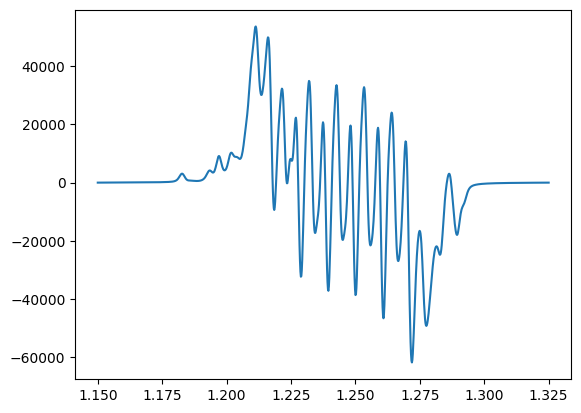

In [15]:
plt.plot(fields, out)

In [18]:
save_case(1, sample_Mn, creator, fields, out)


In [19]:
computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

time_spectrum_calculation_full_pipeline(
    sample_creation_func=create_1_high_spin_electron_1_nuclei_sample,
    sample_kwargs = {"mesh": mesh, "device": device, "dtype": dtype},
    freq=freq, field_range=field_range, n_points=n_points, temperature=temperature,
    computational_details=computational_details,
    n_warmup=2, n_iterations=5,
)

(810.2154400054133,
 32.6562666453264,
 [799.6286999987205,
  790.5834000121104,
  840.8615000080317,
  765.8690999960527,
  854.134500012151])

### Sample 2

In [22]:
sample_hetero_spins = create_heterospin_sample(mesh=mesh, device=device, dtype=dtype)

freq = 35.0 * 1e9
field_range = (1.21, 1.29)
n_points = 1000
temperature = 300.0

fields = torch.linspace(
            field_range[0],
            field_range[1],
            n_points,
            device=device,
            dtype=dtype
        )

computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

creator = spectra_manager.StationarySpectra(
    freq=freq,
    sample=sample_hetero_spins,
    temperature=temperature,
    computational_details=computational_details,
    device=device,
    dtype=dtype
)
    
out = creator(sample=sample_hetero_spins, fields=fields)

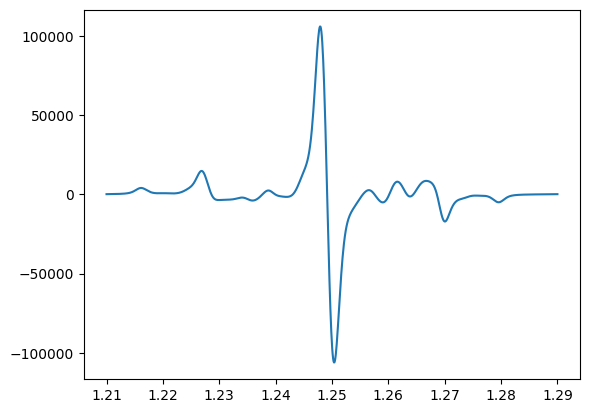

In [23]:
plt.plot(fields, out)

In [24]:
save_case(2, sample_hetero_spins, creator, fields, out)


D:\ITC\РНФ_Курганский_2024\pythonProject\MarS\mars\save_procedures\general_procedures.py:52: UserWarning: Not all MaRs objects can be saved to EasySpin format. Computational parameters (e.g. thresholds, EasySpin Opt) are not saved. Such save support will not continue to develop in MaRs
  return format_handlers[format_type](filepath, sample, spectra_creator, field)


In [25]:
computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

time_spectrum_calculation_full_pipeline(
    sample_creation_func=create_heterospin_sample,
    sample_kwargs = {"mesh": mesh, "device": device, "dtype": dtype},
    freq=freq, field_range=field_range, n_points=n_points, temperature=temperature,
    computational_details=computational_details,
    n_warmup=2, n_iterations=5,
)

(584.9946000002092,
 12.341160292921229,
 [584.7046999988379,
  587.5710999971488,
  581.2000000005355,
  604.9744000047212,
  566.5227999998024])

### Sample 3: SPIN POLARIZED

In [ ]:
sample_2_triplets = create_tripletfission_sample(mesh=mesh, device=device, dtype=dtype)

freq = 9.8 * 1e9
field_range = (0.33, 0.37)
n_points = 1000
temperature = 300.0

fields = torch.linspace(
            field_range[0],
            field_range[1],
            n_points,
            device=device,
            dtype=dtype
        )

computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

init_populations=[0.0] * 9
init_populations[-3] = 1.0
def triplet_context(sample):
    return mars.population.Context(sample=sample, init_populations=init_populations, dtype=dtype, device=device)

context = triplet_context(sample_2_triplets)

creator = spectra_manager.StationarySpectra(
    freq=freq,
    sample=sample_2_triplets,
    context=context,
    temperature=temperature,
    computational_details=computational_details,
    harmonic=0,
    device=device,
    dtype=dtype
)
    
out = creator(sample=sample_2_triplets, fields=fields)

In [ ]:
plt.plot(fields, out)

In [ ]:
save_case(3, sample_2_triplets, creator, fields, out)


In [ ]:
computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

time_spectrum_calculation_full_pipeline(
    sample_creation_func=create_tripletfission_sample,
    context=triplet_context,
    sample_kwargs = {"mesh": mesh, "device": device, "dtype": dtype},
    freq=freq, field_range=field_range, n_points=n_points, temperature=temperature,
    computational_details=computational_details,
    n_warmup=2, n_iterations=5,
)

### Sample 4: Polarized Radiation

In [18]:
sample_hetero = create_heterospin_sample_freq_domain(mesh=mesh, device=device, dtype=dtype)

n_points = 1000
temperature = 300.0

freq_range = (0.0, constants.unit_converter(25.0, "cm-1_to_Hz"))
freq = torch.linspace(
            freq_range[0],
            freq_range[1],
            n_points,
            device=device,
            dtype=dtype
        )

field = torch.tensor(10.0, device=device, dtype=dtype)

computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-3, res_field_r_tol=1e-4)


intensity_calculator = spectra_manager.WaveIntensityCalculator(
    spin_system_dim=sample_hetero.spin_system_dim,  # spin_system_dim from a sample
    disordered=sample_hetero.mesh.disordered,  # True for powder samples
    temperature=temperature,
    magnetization_config=spectra_manager.WaveMagnetizationConfig(
        polarization='+1', theta=0.0,  # k parallel to the static field
    ),
    device=device,
    dtype=dtype,
)

creator = spectra_manager.StationaryFreqSpectra(
    intensity_calculator=intensity_calculator,
    field=field,
    sample=sample_hetero,
    temperature=temperature,
    computational_details=computational_details,
    harmonic=0,
    device=device,
    dtype=dtype
)
    
out = creator(sample=sample_hetero, freq=freq)

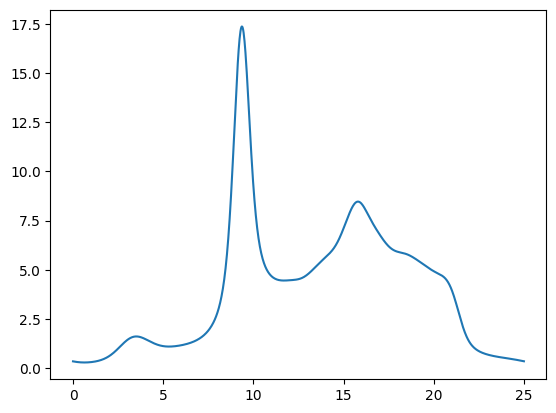

In [19]:
plt.plot(constants.unit_converter(freq, "Hz_to_cm-1"), out)

In [ ]:
save_case(4, sample_hetero, creator, freq, out, frequency_sweep=True)


In [ ]:
computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

intensity_calculator = spectra_manager.WaveIntensityCalculator(
    spin_system_dim=sample_hetero.spin_system_dim,  # spin_system_dim from a sample
    disordered=sample_hetero.mesh.disordered,  # True for powder samples
    temperature=temperature,
    magnetization_config=spectra_manager.WaveMagnetizationConfig(
        polarization='+1', theta=0.0,  # k parallel to the static field
    ),
    device=device,
    dtype=dtype,
)
creator_kwargs = {"intensity_calculator": intensity_calculator}

time_spectrum_calculation_full_pipeline_freqdep(
    sample_creation_func=create_heterospin_sample_freq_domain,
    sample_kwargs = {"mesh": mesh, "device": device, "dtype": dtype},
    creator_kwargs=creator_kwargs,
    field=field, freq_range=freq_range, n_points=n_points, temperature=temperature,
    computational_details=computational_details,
    n_warmup=2, n_iterations=5,
)

# 2. Plot Spectra Together

In [6]:
computational_details = spectra_manager.ComputationalDetails(intensity_threshold=1e-4, res_field_r_tol=1e-4)

def read_csv(name: str):
    data = np.loadtxt(EASYSPIN_SPECTRA / f"{name}.csv", delimiter=",")
    # Support the historical 2-row files without discarding the first point.
    if data.shape[0] == 2 and data.shape[1] != 2:
        data = data.T
    return (torch.tensor(data[:, 0], dtype=dtype, device=device),
            torch.tensor(data[:, 1], dtype=dtype, device=device))


### Sample 1

In [7]:
name = "spec_easy_spin_1"
freq = 35.0 * 1e9
fields, spectrum_easyspin = read_csv(name)
temperature = 300.0

sample_Mn = create_1_high_spin_electron_1_nuclei_sample(mesh=mesh, device=device, dtype=dtype)
creator = spectra_manager.StationarySpectra(
    freq=freq,
    sample=sample_Mn,
    temperature=temperature,
    computational_details=computational_details,
    device=device,
    dtype=dtype
)

out = creator(sample=sample_Mn, fields=fields)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


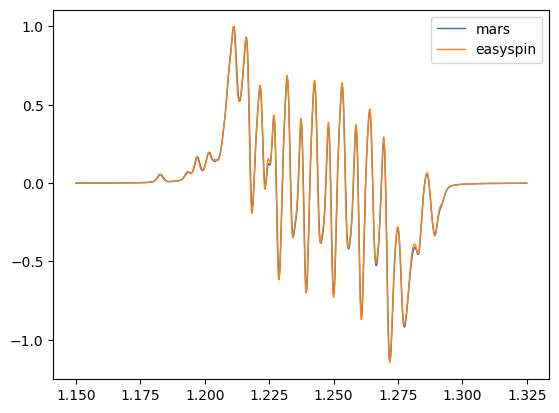

In [8]:
plt.plot(fields, out/ max(out), label="mars", linewidth=1)
plt.plot(fields, spectrum_easyspin / max(spectrum_easyspin), label="easyspin", linewidth=1)
plt.legend()
plt.savefig(FIGURES / "example_1.eps")
plt.show()

### Sample 2

In [ ]:
name = "spec_easy_spin_2"
freq = 35.0 * 1e9
fields, spectrum_easyspin = read_csv(name)
temperature = 300.0

sample_hetero_spins = create_heterospin_sample(mesh=mesh, device=device, dtype=dtype)
creator = spectra_manager.StationarySpectra(
    freq=freq,
    sample=sample_hetero_spins,
    temperature=temperature,
    computational_details=computational_details,
    device=device,
    dtype=dtype
)

out = creator(sample=sample_hetero_spins, fields=fields)

In [ ]:
plt.plot(fields, out/ max(out), label="mars", linewidth=1)
plt.plot(fields, spectrum_easyspin / max(spectrum_easyspin), label="easyspin", linewidth=1)
plt.legend()
plt.savefig(FIGURES / "example_2.eps")
plt.show()

### Sample 3: Sample Polarized

In [29]:
name = "spec_easy_spin_3"
freq = 9.8 * 1e9
fields, spectrum_easyspin = read_csv(name)
temperature = 300.0


sample_2_triplets = create_tripletfission_sample(mesh=mesh, device=device, dtype=dtype)

init_populations=[0.0] * 9
init_populations[-3] = 1.0
context = mars.population.Context(sample=sample_2_triplets, init_populations=init_populations, dtype=dtype, device=device)

creator = spectra_manager.StationarySpectra(
    context=context,
    freq=freq,
    sample=sample_2_triplets,
    temperature=temperature,
    harmonic=0,
    computational_details=computational_details,
    device=device,
    dtype=dtype
)

out = creator(sample=sample_2_triplets, fields=fields)

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


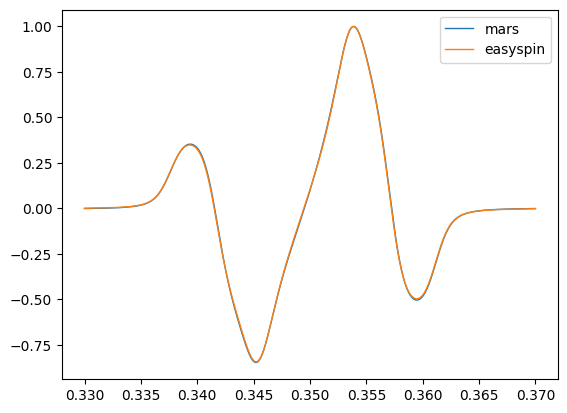

In [30]:
plt.plot(fields, out/ max(out), label="mars", linewidth=1)
plt.plot(fields, spectrum_easyspin / max(spectrum_easyspin), label="easyspin", linewidth=1)
plt.legend()
plt.savefig(FIGURES / "example_3.eps")
plt.show()

### Sample 4: Polarized Radiation


In [ ]:
# Frequency grid is loaded in the next cell.


In [20]:
name = "spec_easy_spin_4"
field = 10.0
freq, spectrum_easyspin = read_csv(name)
freq = freq * 1e9  # EasySpin CSV uses GHz
temperature = 300.0

sample_hetero = create_heterospin_sample_freq_domain(mesh=mesh, device="cpu", dtype=dtype)

intensity_calculator = spectra_manager.WaveIntensityCalculator(
    spin_system_dim=sample_hetero.spin_system_dim,  # spin_system_dim from a sample
    disordered=sample_hetero.mesh.disordered,  # True for powder samples
    temperature=temperature,
    magnetization_config=spectra_manager.WaveMagnetizationConfig(
        polarization='+1', theta=0.0,  # k parallel to the static field
    ),
    device=device,
    dtype=dtype,
)

creator = spectra_manager.StationaryFreqSpectra(
    intensity_calculator=intensity_calculator,
    field=field,
    sample=sample_hetero,
    temperature=temperature,
    computational_details=computational_details,
    harmonic=0,
    device=device,
    dtype=dtype
)

out = creator(sample=sample_hetero, freq=freq)

In [ ]:
freq_cm = constants.unit_converter(freq, "Hz_to_cm-1")
plt.plot(freq_cm, out/ max(out), label="mars", linewidth=1)
plt.plot(freq_cm, spectrum_easyspin / max(spectrum_easyspin), label="easyspin", linewidth=1)
plt.legend()
plt.savefig(FIGURES / "example_4.eps")
plt.show()